In [1]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler

%matplotlib inline

In [2]:
# Load Cleaned Dataset
base_dir = Path.cwd().resolve()
if not (base_dir / "Data").exists():
    base_dir = base_dir.parent

path = (base_dir / "Data" / "Turbofan_Engine_Degradation_Dataset.csv").resolve()
df = pd.read_csv(path)

df = df.drop_duplicates().copy()

# Keep a clean working dataframe for preprocessing
processed_df = df.copy()

print("Dataset shape:", processed_df.shape)
processed_df.head()

Dataset shape: (61249, 27)


,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,318
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,317
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,316


cycle: outliers = 522, bounds = (-131.500, 384.500)
op_setting_1: outliers = 0, bounds = (-37.986, 89.988)
op_setting_2: outliers = 0, bounds = (-0.633, 1.724)
op_setting_3: outliers = 9139, bounds = (100.000, 100.000)
sensor_1: outliers = 0, bounds = (375.715, 560.475)
sensor_2: outliers = 0, bounds = (462.720, 693.680)


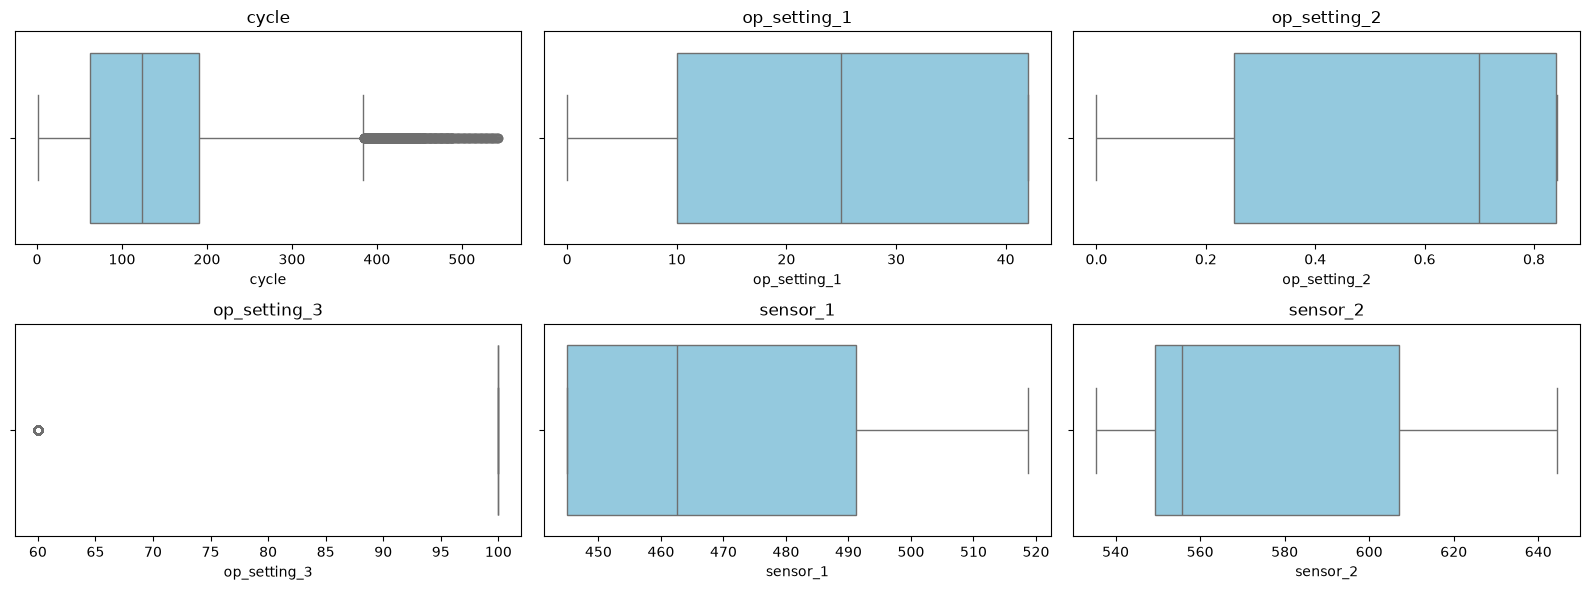

In [3]:
# Detect and Visualize Outliers
numeric_cols = processed_df.select_dtypes(include=[np.number]).columns.tolist()
# Exclude ID-like and target fields from IQR detection for modeling
feature_cols = [col for col in numeric_cols if col not in ['engine_id', 'RUL']]

for col in feature_cols[:6]:
    q1 = processed_df[col].quantile(0.25)
    q3 = processed_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((processed_df[col] < lower) | (processed_df[col] > upper)).sum()
    print(f"{col}: outliers = {outlier_count}, bounds = ({lower:.3f}, {upper:.3f})")

plt.figure(figsize=(16, 6))
for i, col in enumerate(feature_cols[:6], 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=processed_df, x=col, color='skyblue')
    plt.title(col)
plt.tight_layout()
plt.show()

In [4]:
# Remove or Cap Outliers
for col in feature_cols:
    q1 = processed_df[col].quantile(0.25)
    q3 = processed_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    processed_df[col] = processed_df[col].clip(lower=lower, upper=upper)

print("Outlier handling complete.")
print("Shape after clipping:", processed_df.shape)
processed_df[feature_cols[:6]].describe().T

Outlier handling complete.
Shape after clipping: (61249, 27)


,count,mean,std,min,25%,50%,75%,max
cycle,61249.0,133.905549,88.460378,1.00,62.0000,123.0000,191.0000,384.500
op_setting_1,61249.0,23.999823,14.780722,0.00,10.0046,25.0014,41.9981,42.008
op_setting_2,61249.0,0.571347,0.310703,0.00,0.2507,0.7000,0.8400,0.842
op_setting_3,61249.0,100.000000,0.000000,100.00,100.0000,100.0000,100.0000,100.000
sensor_1,61249.0,472.882435,26.436832,445.00,445.0000,462.5400,491.1900,518.670
sensor_2,61249.0,579.420056,37.342647,535.48,549.3300,555.7400,607.0700,644.420


In [5]:
# Apply Feature Scaling (Standardization & Normalization)
X = processed_df[feature_cols].copy()

std_scaler = StandardScaler()
X_standardized = pd.DataFrame(std_scaler.fit_transform(X), columns=X.columns, index=X.index)

minmax_scaler = MinMaxScaler()
X_normalized = pd.DataFrame(minmax_scaler.fit_transform(X), columns=X.columns, index=X.index)

print("Standardized features shape:", X_standardized.shape)
print("Normalized features shape:", X_normalized.shape)
X_standardized.head()

Standardized features shape: (61249, 25)
Normalized features shape: (61249, 25)


,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,-1.502443,1.218156,0.864668,0.0,-1.054690,-0.796416,-0.701412,-0.745729,-1.137677,-1.081831,...,-0.989007,-0.101496,-0.100142,0.178439,-0.694278,-0.638665,-0.338837,0.0,-1.030999,-1.031756
1,-1.491138,-0.270478,0.414718,0.0,0.692508,0.713666,0.562449,0.298212,0.363906,0.371152,...,0.331131,-1.053853,-0.593772,-0.050433,-0.694278,0.476120,0.719395,0.0,0.352814,0.358264
2,-1.479833,1.218082,0.867565,0.0,-1.054690,-0.815965,-0.704332,-0.711202,-1.137677,-1.083668,...,-0.990162,-0.174754,-0.241351,0.286598,-0.694278,-0.674626,-0.338837,0.0,-1.045089,-1.022649
3,-1.468529,1.217824,0.864668,0.0,-1.054690,-0.822660,-0.722040,-0.702990,-1.137677,-1.081831,...,-0.988862,0.008391,-0.079158,0.183912,-0.694278,-0.710586,-0.338837,0.0,-1.039051,-1.023269
4,-1.457224,0.068094,0.158844,0.0,-0.391216,-1.160079,-1.532181,-1.410627,-0.270955,-0.475656,...,-0.741097,-1.823064,-2.005522,1.963386,-0.694278,-1.537685,-1.926184,0.0,-0.687814,-0.644612


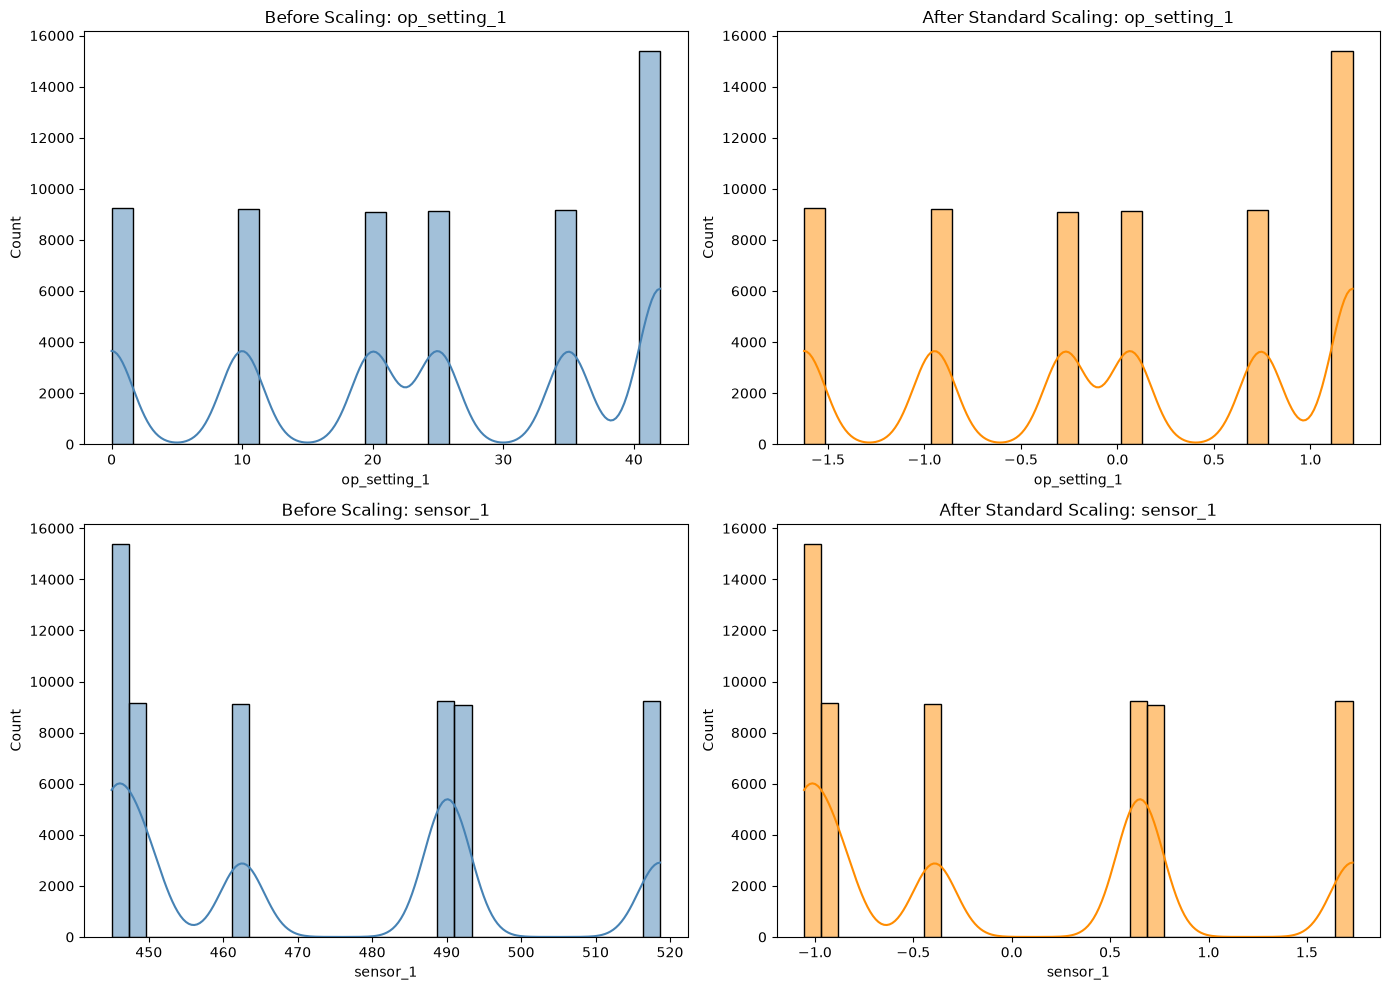

Mean of standardized op_setting_1: 8.503450265508881e-17
Std of standardized op_setting_1: 1.000008163498549
Min of normalized op_setting_1: 0.0
Max of normalized op_setting_1: 1.0


In [6]:
# Compare Data Before and After Scaling
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(X['op_setting_1'], kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Before Scaling: op_setting_1')

sns.histplot(X_standardized['op_setting_1'], kde=True, ax=axes[0, 1], color='darkorange')
axes[0, 1].set_title('After Standard Scaling: op_setting_1')

sns.histplot(X['sensor_1'], kde=True, ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Before Scaling: sensor_1')

sns.histplot(X_standardized['sensor_1'], kde=True, ax=axes[1, 1], color='darkorange')
axes[1, 1].set_title('After Standard Scaling: sensor_1')

plt.tight_layout()
plt.show()

print("Mean of standardized op_setting_1:", X_standardized['op_setting_1'].mean())
print("Std of standardized op_setting_1:", X_standardized['op_setting_1'].std())
print("Min of normalized op_setting_1:", X_normalized['op_setting_1'].min())
print("Max of normalized op_setting_1:", X_normalized['op_setting_1'].max())

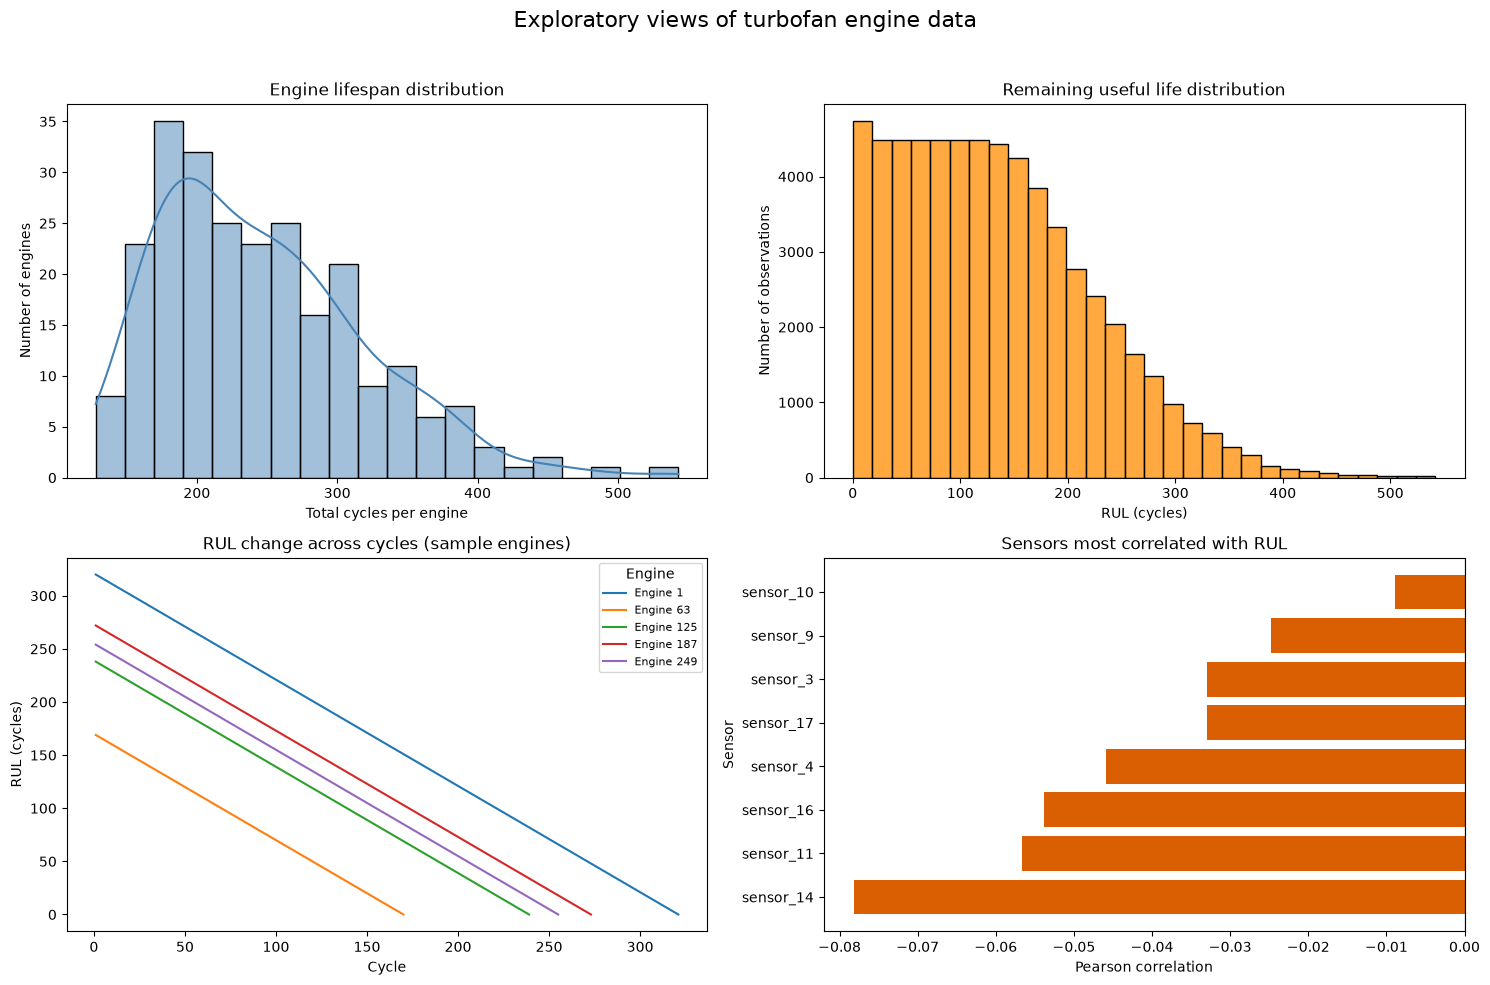

Engines: 249
Observations: 61,249
Cycle range: 1-543
RUL range: 0-542 cycles


In [3]:
# Exploratory visuals: fleet lifetimes, RUL, sample degradation trends, and sensor relationships.
engine_life_cycles = df.groupby("engine_id")["cycle"].max()
engine_ids = np.sort(df["engine_id"].unique())
sample_count = min(5, len(engine_ids))
sample_indices = np.linspace(0, len(engine_ids) - 1, num=sample_count, dtype=int)
sample_engine_ids = engine_ids[sample_indices]

sensor_cols = [col for col in df.columns if col.startswith("sensor_")]
sensor_rul_corr = df[sensor_cols + ["RUL"]].corr(numeric_only=True)["RUL"].drop("RUL").dropna()
top_sensor_corr = sensor_rul_corr.loc[sensor_rul_corr.abs().nlargest(8).index].sort_values()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(engine_life_cycles, bins=20, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set(title="Engine lifespan distribution", xlabel="Total cycles per engine", ylabel="Number of engines")

sns.histplot(df["RUL"], bins=30, ax=axes[0, 1], color="darkorange")
axes[0, 1].set(title="Remaining useful life distribution", xlabel="RUL (cycles)", ylabel="Number of observations")

for engine_id in sample_engine_ids:
    engine_data = df.loc[df["engine_id"] == engine_id]
    axes[1, 0].plot(engine_data["cycle"], engine_data["RUL"], label=f"Engine {engine_id}", linewidth=1.5)
axes[1, 0].set(title="RUL change across cycles (sample engines)", xlabel="Cycle", ylabel="RUL (cycles)")
axes[1, 0].legend(title="Engine", fontsize=8)

corr_colors = ["#d95f02" if value < 0 else "#1b9e77" for value in top_sensor_corr]
axes[1, 1].barh(top_sensor_corr.index, top_sensor_corr.values, color=corr_colors)
axes[1, 1].axvline(0, color="black", linewidth=0.8)
axes[1, 1].set(title="Sensors most correlated with RUL", xlabel="Pearson correlation", ylabel="Sensor")

fig.suptitle("Exploratory views of turbofan engine data", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
plt.close(fig)

print(f"Engines: {len(engine_life_cycles):,}")
print(f"Observations: {len(df):,}")
print(f"Cycle range: {df['cycle'].min()}-{df['cycle'].max()}")
print(f"RUL range: {df['RUL'].min()}-{df['RUL'].max()} cycles")
